In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

from sklearn.pipeline import Pipeline
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error


In [2]:
data=pd.read_csv('crop_yield.csv')
data

,Crop,Crop_Year,Season,State,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
0,Arecanut,1997,Whole Year,Assam,73814.0,56708,2051.4,7024878.38,22882.34,0.796087
1,Arhar/Tur,1997,Kharif,Assam,6637.0,4685,2051.4,631643.29,2057.47,0.710435
2,Castor seed,1997,Kharif,Assam,796.0,22,2051.4,75755.32,246.76,0.238333
3,Coconut,1997,Whole Year,Assam,19656.0,126905000,2051.4,1870661.52,6093.36,5238.051739
4,Cotton(lint),1997,Kharif,Assam,1739.0,794,2051.4,165500.63,539.09,0.420909
...,...,...,...,...,...,...,...,...,...,...
19684,Small millets,1998,Kharif,Nagaland,4000.0,2000,1498.0,395200.00,1160.00,0.500000
19685,Wheat,1998,Rabi,Nagaland,1000.0,3000,1498.0,98800.00,290.00,3.000000
19686,Maize,1997,Kharif,Jammu and Kashmir,310883.0,440900,1356.2,29586735.11,96373.73,1.285000
19687,Rice,1997,Kharif,Jammu and Kashmir,275746.0,5488,1356.2,26242746.82,85481.26,0.016667


In [3]:
data.shape

(19689, 10)

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19689 entries, 0 to 19688
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Crop             19689 non-null  object 
 1   Crop_Year        19689 non-null  int64  
 2   Season           19689 non-null  object 
 3   State            19689 non-null  object 
 4   Area             19689 non-null  float64
 5   Production       19689 non-null  int64  
 6   Annual_Rainfall  19689 non-null  float64
 7   Fertilizer       19689 non-null  float64
 8   Pesticide        19689 non-null  float64
 9   Yield            19689 non-null  float64
dtypes: float64(5), int64(2), object(3)
memory usage: 1.5+ MB


In [5]:
(data.isnull().sum()/len(data))*100

,0
Crop,0.0
Crop_Year,0.0
Season,0.0
State,0.0
Area,0.0
Production,0.0
Annual_Rainfall,0.0
Fertilizer,0.0
Pesticide,0.0
Yield,0.0


In [6]:
data.describe()

,Crop_Year,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
count,19689.000000,1.968900e+04,1.968900e+04,19689.000000,1.968900e+04,1.968900e+04,19689.000000
mean,2009.127584,1.799266e+05,1.643594e+07,1437.755177,2.410331e+07,4.884835e+04,79.954009
std,6.498099,7.328287e+05,2.630568e+08,816.909589,9.494600e+07,2.132874e+05,878.306193
min,1997.000000,5.000000e-01,0.000000e+00,301.300000,5.417000e+01,9.000000e-02,0.000000
25%,2004.000000,1.390000e+03,1.393000e+03,940.700000,1.880146e+05,3.567000e+02,0.600000
50%,2010.000000,9.317000e+03,1.380400e+04,1247.600000,1.234957e+06,2.421900e+03,1.030000
75%,2015.000000,7.511200e+04,1.227180e+05,1643.700000,1.000385e+07,2.004170e+04,2.388889
max,2020.000000,5.080810e+07,6.326000e+09,6552.700000,4.835407e+09,1.575051e+07,21105.000000


In [7]:
corr=data.corr(numeric_only=True)
corr

,Crop_Year,Area,Production,Annual_Rainfall,Fertilizer,Pesticide,Yield
Crop_Year,1.000000,-0.035686,0.003366,-0.011187,0.011169,-0.004657,0.002539
Area,-0.035686,1.000000,0.037441,-0.106054,0.973255,0.973479,0.001858
Production,0.003366,0.037441,1.000000,0.029879,0.039799,0.035171,0.570809
Annual_Rainfall,-0.011187,-0.106054,0.029879,1.000000,-0.109734,-0.097657,0.020761
Fertilizer,0.011169,0.973255,0.039799,-0.109734,1.000000,0.954991,0.002862
Pesticide,-0.004657,0.973479,0.035171,-0.097657,0.954991,1.000000,0.001782
Yield,0.002539,0.001858,0.570809,0.020761,0.002862,0.001782,1.000000


<Axes: >

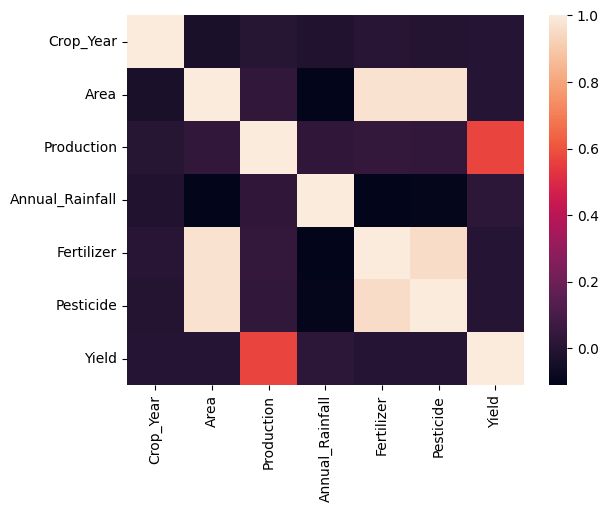

In [8]:
sns.heatmap(corr)

In [9]:
data.duplicated().sum()

np.int64(0)

In [10]:
data.columns

Index(['Crop', 'Crop_Year', 'Season', 'State', 'Area', 'Production',
       'Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield'],
      dtype='object')

In [11]:
cat=['Crop',  'Season', 'State']
num=['Crop_Year', 'Area', 'Production','Annual_Rainfall', 'Fertilizer', 'Pesticide', 'Yield']

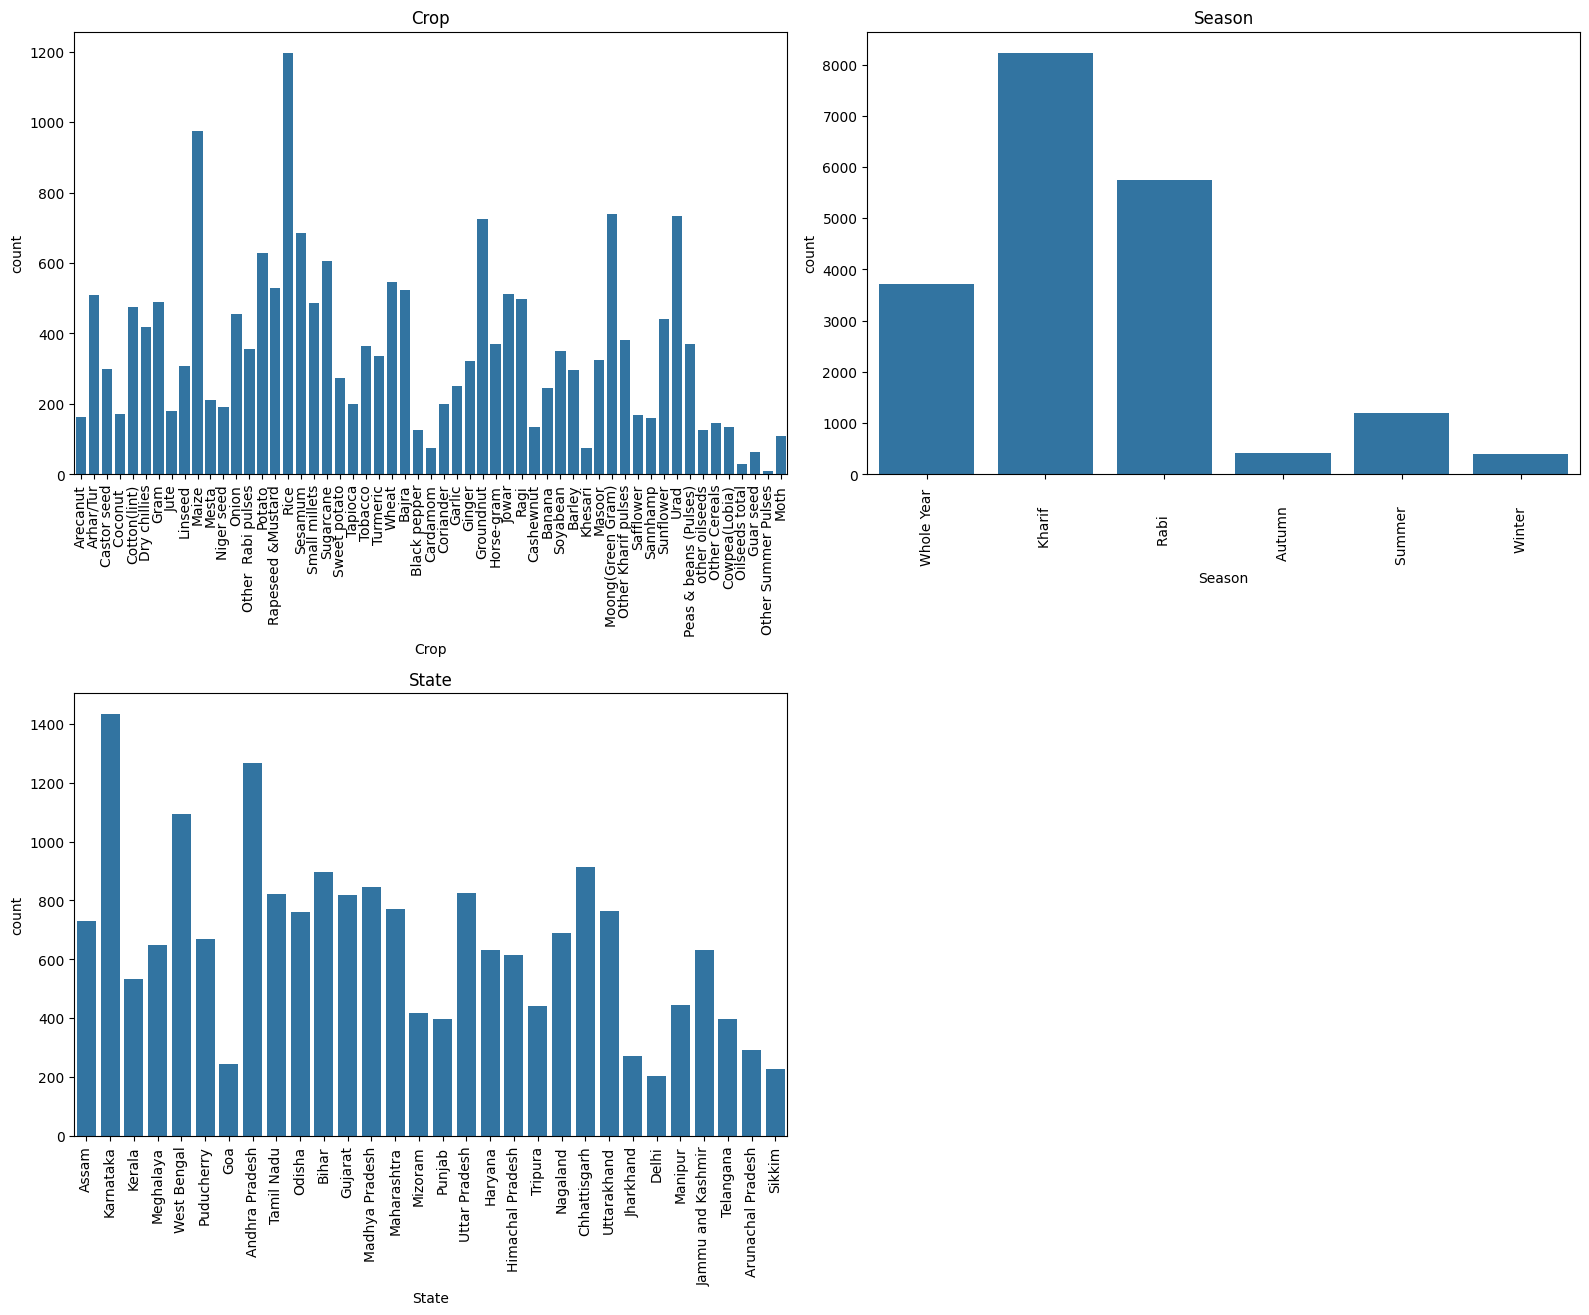

In [12]:
plt.figure(figsize=(16,12))

for index,col in enumerate(cat):
  plt.subplot(2,2,index+1)
  sns.countplot(x=data[col])
  plt.title(col)
  plt.tight_layout()
  plt.xticks(rotation=90)
plt.show()

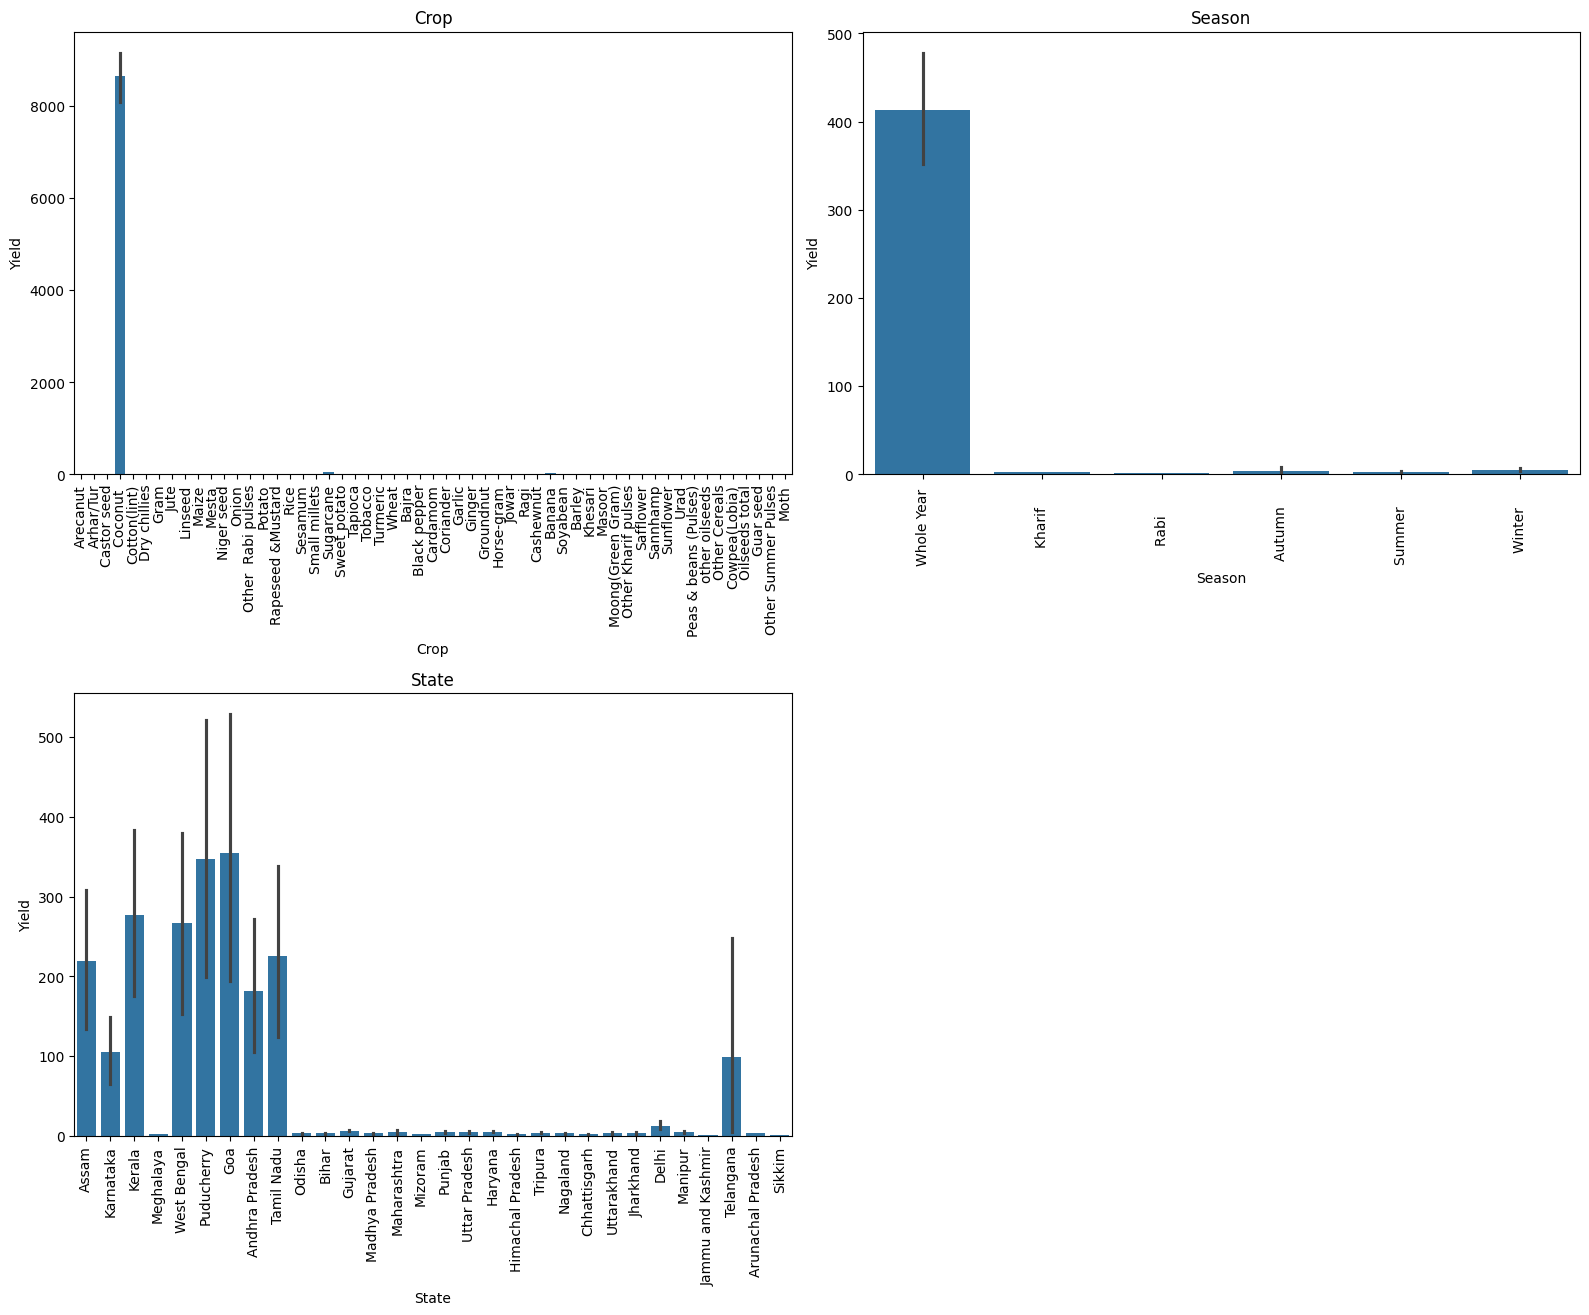

In [13]:
plt.figure(figsize=(16,12))

for index,col in enumerate(col for col in cat if col!='Yield'):
  plt.subplot(2,2,index+1)
  sns.barplot(x=data[col],y=data['Yield'])
  plt.title(col)
  plt.tight_layout()
  plt.xticks(rotation=90)
plt.show()

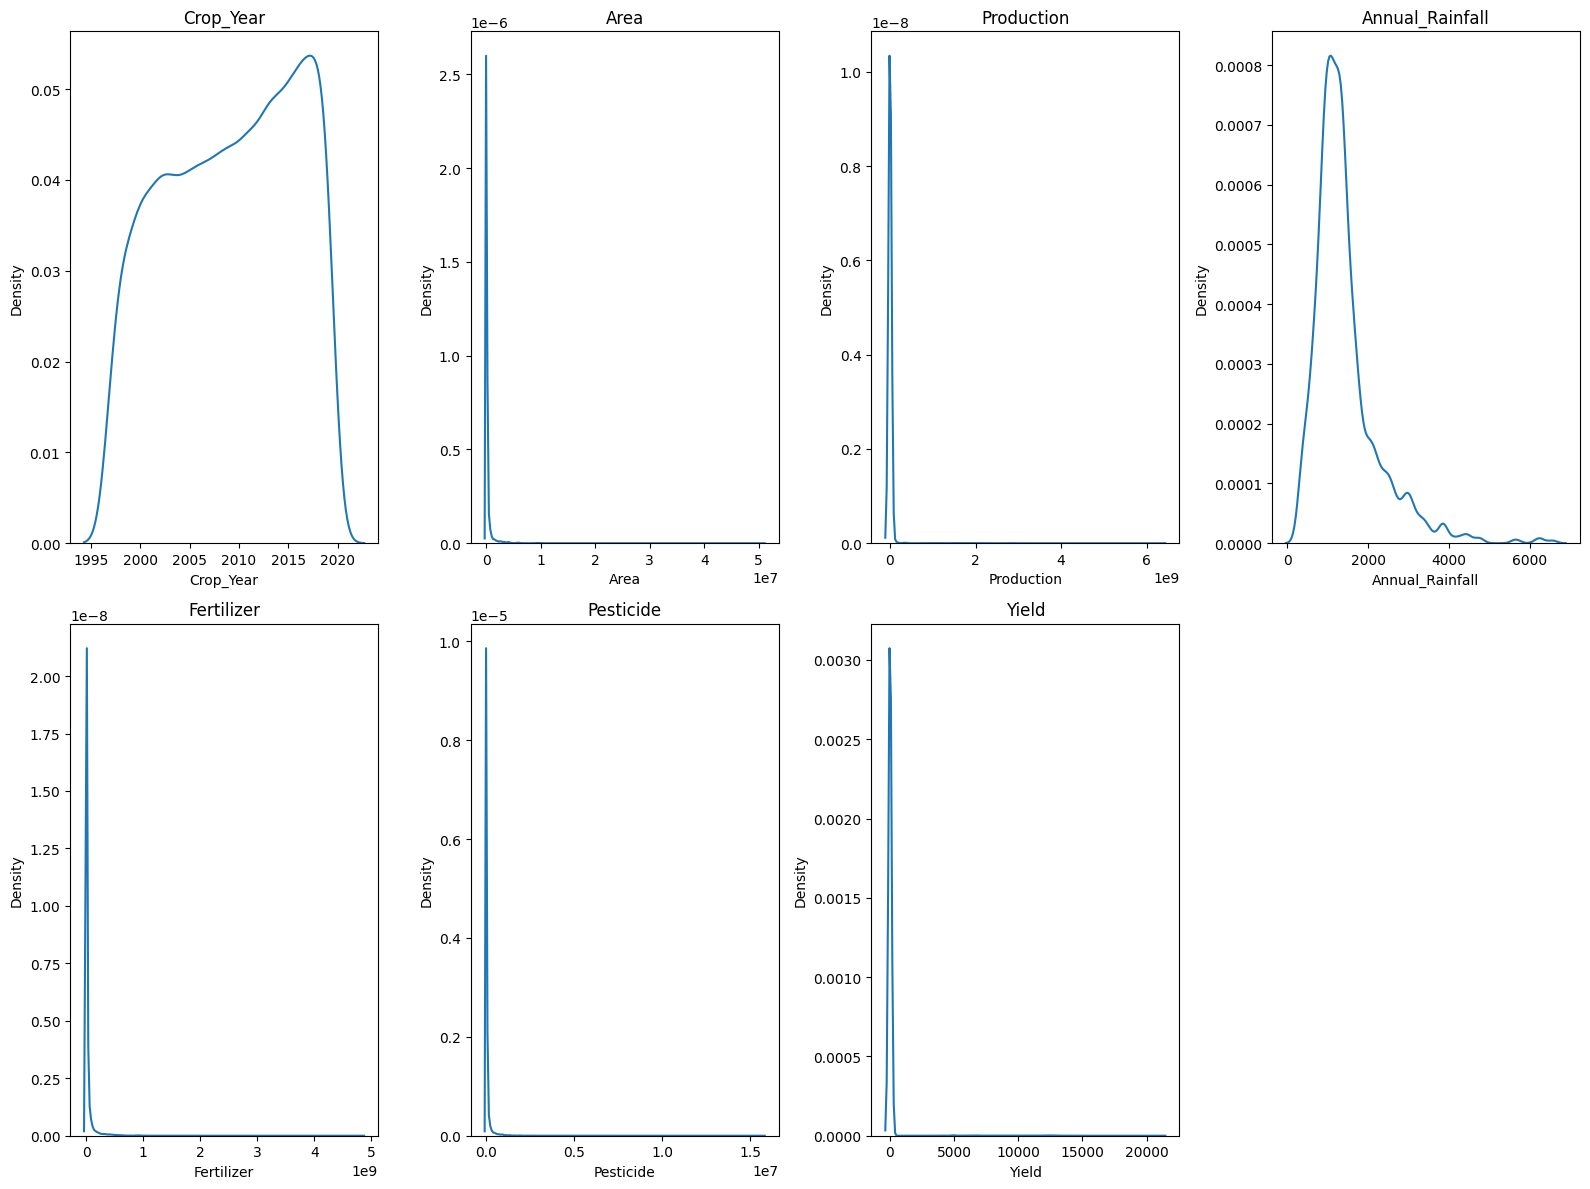

In [14]:
plt.figure(figsize=(16,12))

for index,col in enumerate(num):
  plt.subplot(2,4,index+1)
  sns.kdeplot(data[col])
  plt.tight_layout()
  plt.title(col)
plt.show()

In [15]:
for col in num:
  print(f"skewness in {col}: ",data[col].skew())

skewness in Crop_Year:  -0.16265562121556904
skewness in Area:  21.858217797355426
skewness in Production:  19.299193411606723
skewness in Annual_Rainfall:  2.1317850114644354
skewness in Fertilizer:  13.412598810025766
skewness in Pesticide:  25.635746086843607
skewness in Yield:  12.785264685628691


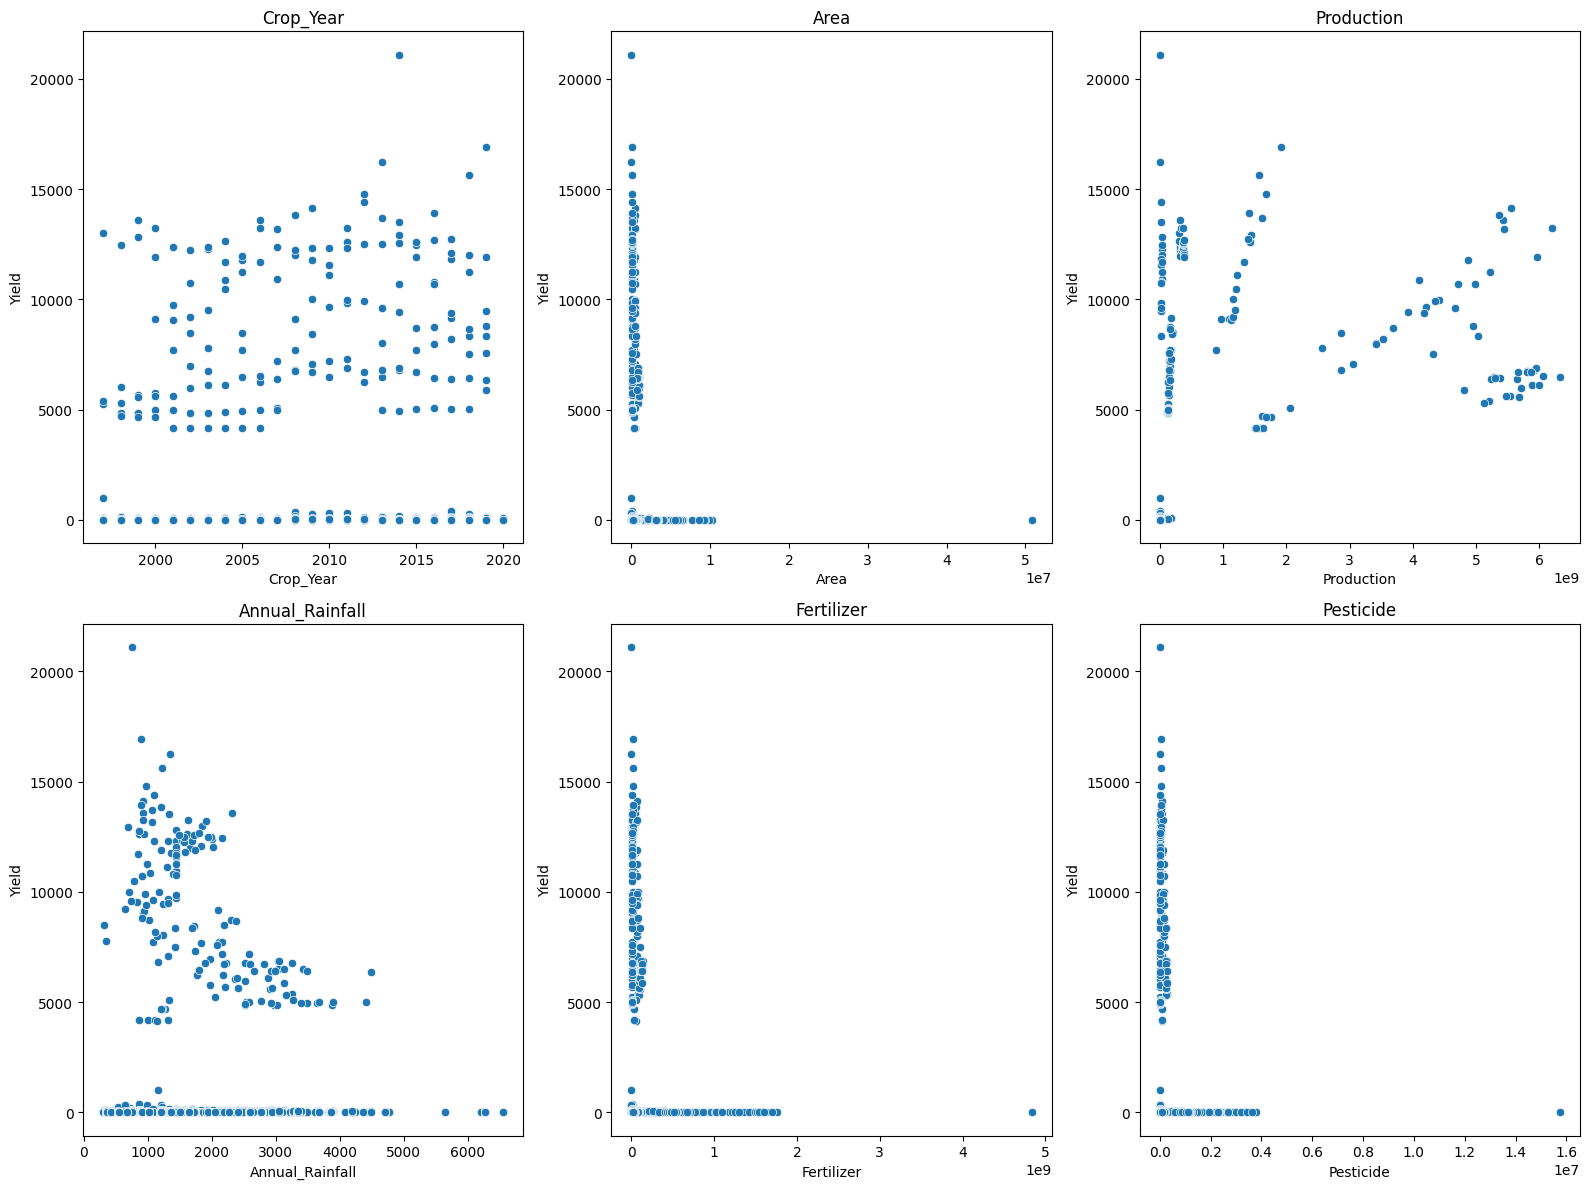

In [16]:
plt.figure(figsize=(16,12))


for index, col in enumerate([col for col in num if col != 'Yield']):
  plt.subplot(2,3,index+1)
  sns.scatterplot(x=data[col], y=data['Yield'])
  plt.tight_layout()
  plt.title(col)
plt.show()

In [17]:
data.drop(columns='Production',inplace=True)

In [18]:
x=data.drop(columns='Yield')
y=data['Yield']

In [19]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [20]:
num_input=['Crop_Year',
 'Area',
 'Annual_Rainfall',
 'Fertilizer',
 'Pesticide']

In [21]:
trf=ColumnTransformer(transformers=[
    ('ohe',OneHotEncoder(),['Crop',  'Season', 'State']),
    ('scale',StandardScaler(),num_input)
],remainder='passthrough')

In [22]:
pipe=Pipeline([
    ('trf',trf),
    ('lr',RandomForestRegressor())
])

In [23]:
pipe.fit(x_train,y_train)

Pipeline(steps=[('trf',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('ohe', OneHotEncoder(),
                                                  ['Crop', 'Season', 'State']),
                                                 ('scale', StandardScaler(),
                                                  ['Crop_Year', 'Area',
                                                   'Annual_Rainfall',
                                                   'Fertilizer',
                                                   'Pesticide'])])),
                ('lr', RandomForestRegressor())])

In [24]:
y_pred=pipe.predict(x_test)

In [25]:
r2_score(y_test,y_pred)

0.9792520024804476

In [26]:
mean_absolute_error(y_test,y_pred)


9.60254833929867

In [29]:
import pickle

with open('crop_yield.pkl','wb') as file:
  pickle.dump(pipe,file)
  print("Pickle file created")

Pickle file created
